# Regression Models

### Name: Albatul Altoum

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Part 1: Logestic regression

#### <font color='purple'> 1)  Write a function to compute sigmoid using the following equation: </font>

![Screen%20Shot%202021-03-18%20at%208.49.22%20AM.png](attachment:Screen%20Shot%202021-03-18%20at%208.49.22%20AM.png)

In [ ]:
def sigmoid(z):
  ## write your code here
  return 1 / (1 + np.exp(-z))

In [ ]:
z=np.array([0,2., -1, 22, 100])
print(sigmoid(z))

[0.5        0.88079708 0.26894142 1.         1.        ]


#### <font color='purple'> 2)  Write a function to compute the loss using the following formula </font>

![Screen%20Shot%202021-03-18%20at%208.53.29%20AM.png](attachment:Screen%20Shot%202021-03-18%20at%208.53.29%20AM.png)

In [1]:
import numpy as np

def loss_fun(y, y_bar):
    m = len(y)
    return -(1 / m) * (np.dot(y, np.log(y_bar)) + np.dot((1 - y), np.log(1 - y_bar)))
# Example usage:
y = np.array([1, 0, 1, 0])        # Correct outputs
y_bar = np.array([0.9, 0.1, 0.8, 0.2])  # Predicted outputs
print(loss_fun(y, y_bar))

0.164252033486018


#### <font color='purple'> 3)  Write a function to compute the gradient using the following equation: </font>

In [ ]:


## y correct outputs
## y_bar: predicted outputs
def loss_fun(y, y_bar):
  # write your code here
  import numpy as np

def compute_loss(y, h):
    """‍
    Compute the loss using the given formula for logistic regression.‍
‍
    Parameters:‍
    y (numpy array): Actual labels (0 or 1), shape (m, 1)‍
    h (numpy array): Predicted probabilities, shape (m, 1)‍
‍
    Returns:‍
    float: Computed loss‍
    """
    m = len(y)  # Number of examples‍
    epsilon = 1e-15  # To avoid log(0)‍

    # Clip h to avoid log(0) errors‍
    h = np.clip(h, epsilon, 1 - epsilon)

    loss = -1/m * (np.dot(y.T, np.log(h)) + np.dot((1 - y).T, np.log(1 - h)))
    return loss.item()  # Convert to a scalar‍
    # Example input‍
y = np.array([[1], [0], [1]])  # Actual labels‍
h = np.array([[0.9], [0.1], [0.8]])  # Predicted probabilities‍

# Compute loss‍
loss = compute_loss(y, h)
print("Loss:", loss)





Loss: 0.14462152754328741


![Screen%20Shot%202021-03-18%20at%209.34.57%20AM.png](attachment:Screen%20Shot%202021-03-18%20at%209.34.57%20AM.png)

In [ ]:

def compute_grad(X, y, y_bar):
    # write your code here
    grad = np.dot(X.T, (y_bar - y))
    return grad


In [ ]:
X=np.array([[1,0.77132064, 0.02075195, 0.63364823],
 [1, 1.74880388 ,0.49850701 ,0.22479665],
 [1, 0.19806286, 0.76053071 ,0.16911084],
 [1, 0.08833981 , 3.68535982 , -0.95339335],
 [1, -0.00394827 ,0.51219226 ,0.81262096]])


In [ ]:
print(X.shape)

(5, 4)


In [ ]:
y_bar=np.array([0.5, 0.88079708 ,0.26894142, .1, .3])
y=np.array([1,1,0,1,0])
g=compute_grad(X, y, y_bar)

print(g)

[-0.9502615  -0.62154585 -3.02842742  0.80370068]


#### <font color='purple'> 4)  Write a function to compute $z$ using the following equation: </font>

$ z=X *\theta $

In [ ]:

# $ z=X *\theta $
def f(X, theta):
    ## write your code here
    return np.dot(X, theta)


In [ ]:
theta=np.array([-1, .0, -2., .022])
z=f(X, theta)
print(z)

[-1.02756364 -1.99206849 -2.51734098 -8.39169429 -2.00650686]


#### <font color='purple'> 5)  Write a function to predict class labels for samples in X. </font>

In [ ]:
# #### <font color='purple'> 5)  Write a function to predict class labels for samples in X. </font>
def predict(X, theta):
    ### write your code here
    z = f(X, theta)
    y_bar = sigmoid(z)
    y_pred = [1 if i >= 0.5 else 0 for i in y_bar]
    return y_bar, y_pred

y_bar, y_pred = predict(X,theta)
print(y_bar)
print(y_pred)


[2.63556716e-01 1.20038198e-01 7.46514188e-02 2.26691383e-04
 1.18521435e-01]
[0, 0, 0, 0, 0]


In [ ]:
print(predict(X,theta))

(array([2.63556716e-01, 1.20038198e-01, 7.46514188e-02, 2.26691383e-04,
       1.18521435e-01]), [0, 0, 0, 0, 0])


#### <font color='purple'> 5)  Write a function to compute the accuracy </font>

In [ ]:
# #### <font color='purple'> 5)  Write a function to compute the accuracy </font>
def score(y, y_bar):
    ## write your code there
    accuracy = np.mean(np.array(y) == np.array(y_bar))
    return accuracy

y_true=[1,1,1,0]
y_bar=[1,1,1,1]
print(score(y_true,y_bar))

0.75


## Let’s also define the train function which will be used to find the model parameters that minimizes the cost function using functions above.

[-0.20556075 -0.17509445  0.24367098  0.05111044]


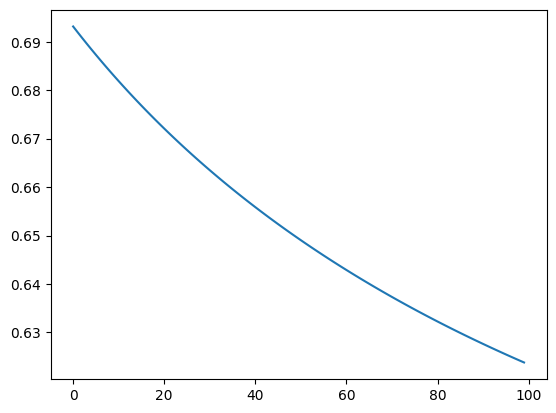

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Define helper functions‍
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

def loss_fun(y, a):
    m = len(y)
    epsilon = 1e-15
    a = np.clip(a, epsilon, 1 - epsilon)
    return -1/m * (np.dot(y.T, np.log(a)) + np.dot((1 - y).T, np.log(1 - a))).item()

def compute_grad(X, y, a):
    m = len(y)
    return (1/m) * np.dot(X.T, (a - y))

# Training function‍
def train(X, y, lr=0.02, iter=100):
    loss = []
    theta = np.zeros(X.shape[1])
    for i in range(iter):
        z = np.dot(X, theta)
        a = sigmoid(z)
        loss_ = loss_fun(y, a)
        g = compute_grad(X, y, a)
        theta = theta - lr * g
        loss.append(loss_)
    print(theta)
    # Plot the loss curve‍
    rr = list(range(iter))
    plt.plot(rr, loss)
    plt.show()

# Input data‍
X = np.array([
    [1, 0.77132064, 0.02075195, 0.63364823],
    [1, 1.74880388, 0.49850701, 0.22479665],
    [1, 0.19806286, 0.76053071, 0.16911084],
    [1, 0.08833981, 3.68359832, 0.95339335],
    [1, -0.00394827, 0.51219226, 0.81262096]
])
y = np.array([1, 0, 0, 1, 0])

# Train the model‍
train(X, y)

#### <font color='purple'> 6)  - Load cancer dataset from sklearn. Split the data into 70% for traing and 30% for testing. Train the training set using train function. Then, cacluate the accuracy on testing set</font>



In [ ]:
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn import metrics
from sklearn import svm

cancer = load_breast_cancer()
cancer.keys()

dict_keys(['data', 'target', 'frame', 'target_names', 'DESCR', 'feature_names', 'filename', 'data_module'])

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(cancer.data, cancer.target,
                                                    test_size=0.3,random_state=5)

In [ ]:
clf = svm.SVC(kernel='linear')
clf.fit(X_train, y_train)
y_pred = clf.predict(X_test)
print("Accuracy:",metrics.accuracy_score(y_test, y_pred))

Accuracy: 0.9824561403508771


# Part 2: Naive Bayes classifier

### You have a set of customers reviews (training set) and a classification as shown in the table below.

In [ ]:
reviews=[['he likes the restaurant'],['he dislikes the restaurant'],['wonderful restaurant'],
         ['great service and fantastic food']]
labels=['positive','negitive','positive','positive' ]


#### <font color='purple'> 1)  Write a function to return the number of all unique words in the training set</font>

In [ ]:

def get_len_of_unique_words(corpus):
    ## write your code here
    unique_words = set()
    for review in corpus:
        for word in review[0].split():
            unique_words.add(word)
    return len(unique_words)


In [ ]:
V=get_len_of_unique_words(reviews)
print(V)

11


#### <font color='purple'> 2)  Write a function to return the number of all words in given class</font>

In [ ]:


# Function to get the length of all words for a given class
def get_length_of_all_words_for_given_class(corpus, all_labels, given_class):
    total_words = 0
    for review, label in zip(corpus, all_labels):
        if label == given_class:
            total_words += len(review[0].split())
    return total_words



In [ ]:

# Test the function for word lengths per class
all_words_len_for_negitive_class = get_length_of_all_words_for_given_class(reviews, labels, given_class='negitive')
print("Total words for 'negitive' class:", all_words_len_for_negitive_class)

all_words_len_for_positive_class = get_length_of_all_words_for_given_class(reviews, labels, given_class='positive')
print("Total words for 'positive' class:", all_words_len_for_positive_class)



Total words for 'negitive' class: 4
Total words for 'positive' class: 11


#### <font color='purple'> 3)  Write a function to return the occurance of given word in spcific class</font>

In [ ]:

# Function to get the occurrence of a given word in a specific class
def get_of_occurance_of_word_in_given_class(word, corpus, labels, given_class):
    occurrence_count = 0
    for review, label in zip(corpus, labels):
        if label == given_class:
            words = review[0].split()
            occurrence_count += words.count(word)
    return occurrence_count



In [ ]:
occurrence = get_of_occurance_of_word_in_given_class('restaurant', reviews, labels, 'negitive')
print("Occurrence of 'restaurant' in 'negitive' class:", occurrence)

Occurrence of 'restaurant' in 'negitive' class: 1


#### <font color='purple'> 4)  Write a function to calculate the  prior probablity for given class</font>

In [ ]:
# Function to calculate the prior probability for a given class
def get_prior_prob(given_class, labels):
    total_count = len(labels)
    class_count = labels.count(given_class)
    return class_count / total_count




In [ ]:

prior_prob = get_prior_prob('negitive', labels)
print("Prior probability of 'negitive' class:", prior_prob)

Prior probability of 'negitive' class: 0.25


#### <font color='purple'> 4)  Write a function to caclulate the likelihood for a word given a class p(word|class)</font>

In [ ]:
# Function to calculate the likelihood for a word given a class p(word|class)
def get_likelihood_for_given_word(corpus, all_labels, word, given_class):
    # Get the total number of unique words (vocabulary size)
    V = get_len_of_unique_words(corpus)

    # Get the total number of words for the given class
    Len_of_all_words_for_given_class = get_length_of_all_words_for_given_class(corpus, all_labels, given_class)

    # Get the occurrence of the word in the given class
    occurance_ = get_of_occurance_of_word_in_given_class(word, corpus, all_labels, given_class)

    # Apply the likelihood formula (Laplace smoothing)
    likelihood = (occurance_ + 1) / (Len_of_all_words_for_given_class + V)

    return likelihood



In [ ]:

likelihood = get_likelihood_for_given_word(reviews, labels, 'restaurant', 'negitive')
print("Likelihood of 'restaurant' given 'negitive' class:", likelihood)



Likelihood of 'restaurant' given 'negitive' class: 0.13333333333333333


# Part 3: Classification using PCA, KNN, and logesitic regression

### LFW dataset
###### The LFW dataset contains 13,233 images of faces collected from the web. This dataset consists of the 5749 identities with 1680 people with two or more images.

In [ ]:
from sklearn.datasets import fetch_lfw_people
import matplotlib.pyplot as plt

In [ ]:
## load lfw dataset
lfw= fetch_lfw_people(min_faces_per_person=10)


In [ ]:
print(lfw.DESCR[:500])

.. _labeled_faces_in_the_wild_dataset:

The Labeled Faces in the Wild face recognition dataset
------------------------------------------------------

This dataset is a collection of JPEG pictures of famous people collected
over the internet, all details are available on the official website:

http://vis-www.cs.umass.edu/lfw/

Each picture is centered on a single face. The typical task is called
Face Verification: given a pair of two pictures, a binary classifier
must predict whether the two ima


In [ ]:
X=lfw.data
X.shape
## image size = 62* 47=2914

(4324, 2914)

### 1- Normalize the input features with mean zero and variance one

In [ ]:
### write your code here
from sklearn.preprocessing import StandardScaler
n_samples, h, w = lfw.images.shape

n_features = X.shape[1]

y = lfw.target
target_names = lfw.target_names
n_classes = target_names.shape[0]

print("Total dataset size:")
print("n_samples: %d" % n_samples)
print("n_features: %d" % n_features)
print("n_classes: %d" % n_classes)

scaler = StandardScaler()
n = scaler.fit_transform(X)
n

Total dataset size:
n_samples: 4324
n_features: 2914
n_classes: 158


array([[ 0.41152003, -0.06687877,  0.060472  , ..., -1.0241618 ,
        -0.9127208 , -0.81910837],
       [-0.49672237,  0.03245161,  0.92383695, ..., -1.4819294 ,
        -1.3790842 , -1.2848815 ],
       [ 0.23915285,  0.04569567,  0.02092857, ..., -0.00791768,
         0.15259957,  0.436652  ],
       ...,
       [-1.2856337 , -0.9211202 , -0.55904174, ..., -0.470263  ,
        -0.40977988, -0.3807338 ],
       [ 0.10656273,  0.03907364, -0.07133943, ...,  1.2463654 ,
         1.1676257 ,  1.2449052 ],
       [-0.54975843, -0.59664094, -0.28882825, ..., -1.2210019 ,
        -1.1504747 , -1.1524558 ]], dtype=float32)

In [ ]:
len(lfw.target_names)

158

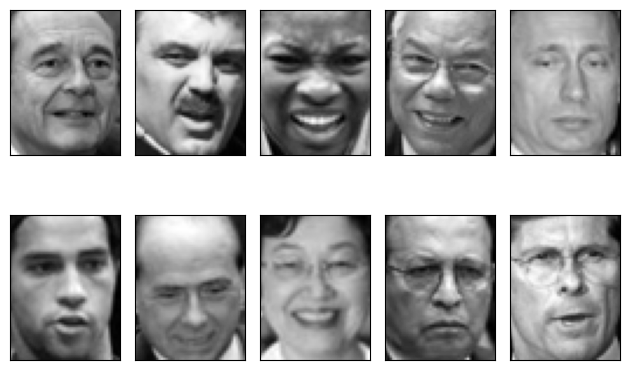

In [ ]:
def plot_faces(images, n_row=2, n_col=5):
    w=47
    h=62
    """Helper function to plot a gallery of portraits"""

    for i in range(n_row * n_col):
        plt.subplot(n_row, n_col, i + 1)
        plt.imshow(images[i].reshape((h, w)), cmap=plt.cm.gray)
        plt.xticks(())
        plt.yticks(())
    plt.tight_layout()
    plt.show()

#plot the average face and some samples from the dataset
plot_faces(X)


### 2- Split data to 70% for training and 30% for testing. Use train_test_split from sklearn with random_state=5

In [ ]:
## write your code here
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size = 0.30, random_state = 5)
print("size of training Data is % d and Testing Data is % d" %(
        y_train.shape[0], y_test.shape[0]))

size of training Data is  3026 and Testing Data is  1298


### 3- Write Python code to implement a face recognition systems using scikit-learn on lfw dataset. These systems include:
1- Logestic regression model  (feed the images [raw features] into the logestic regression directly)<br>
2- PCA + K_NN (number of principle components=100)<br>
3- PCA+ logestic regression( number of principle components=100)<br>
4- K-NN<br>
5- Create a table comparsions to compare the accuracy of the Face recogniton systems above (Note: use tabulate library to print tabular data. For more details: https://pypi.org/project/tabulate/


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

# Logistic regression on raw features
log_reg = LogisticRegression(max_iter=1000)
log_reg.fit(X_train, y_train)

# Evaluate Logistic Regression model
y_pred_log_reg = log_reg.predict(X_test)
accuracy_log_reg = accuracy_score(y_test, y_pred_log_reg)
print(f"Logistic Regression accuracy: {accuracy_log_reg:.4f}")


Logistic Regression accuracy: 0.4630


In [ ]:
from sklearn.decomposition import PCA
from sklearn.neighbors import KNeighborsClassifier

# Apply PCA to reduce dimensionality
pca = PCA(n_components=100)
X_train_pca = pca.fit_transform(X_train)
X_test_pca = pca.transform(X_test)

# KNN with PCA-reduced data
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_pca, y_train)

# Evaluate KNN model
y_pred_knn = knn.predict(X_test_pca)
accuracy_knn = accuracy_score(y_test, y_pred_knn)
print(f"KNN with PCA accuracy: {accuracy_knn:.4f}")


KNN with PCA accuracy: 0.1980


In [ ]:
# Logistic Regression with PCA-reduced data
log_reg_pca = LogisticRegression(max_iter=1000)
log_reg_pca.fit(X_train_pca, y_train)

# Evaluate Logistic Regression model with PCA
y_pred_log_reg_pca = log_reg_pca.predict(X_test_pca)
accuracy_log_reg_pca = accuracy_score(y_test, y_pred_log_reg_pca)
print(f"Logistic Regression with PCA accuracy: {accuracy_log_reg_pca:.4f}")


Logistic Regression with PCA accuracy: 0.4538


In [ ]:
# KNN with raw features (no PCA)
knn_raw = KNeighborsClassifier(n_neighbors=5)
knn_raw.fit(X_train, y_train)

# Evaluate KNN model with raw features
y_pred_knn_raw = knn_raw.predict(X_test)
accuracy_knn_raw = accuracy_score(y_test, y_pred_knn_raw)
print(f"KNN on raw features accuracy: {accuracy_knn_raw:.4f}")


KNN on raw features accuracy: 0.1918


In [ ]:
from tabulate import tabulate

# Create a comparison table
table = [
    ["Logistic Regression (raw features)", accuracy_log_reg],
    ["KNN (raw features)", accuracy_knn_raw],
    ["PCA + Logistic Regression", accuracy_log_reg_pca],
    ["PCA + KNN", accuracy_knn]
]

# Print the table
print(tabulate(table, headers=["Model", "Accuracy"], tablefmt="grid"))


+------------------------------------+------------+
| Model                              |   Accuracy |
+====================================+============+
| Logistic Regression (raw features) |   0.46302  |
+------------------------------------+------------+
| KNN (raw features)                 |   0.191834 |
+------------------------------------+------------+
| PCA + Logistic Regression          |   0.453775 |
+------------------------------------+------------+
| PCA + KNN                          |   0.197997 |
+------------------------------------+------------+


### 4- Plot the decision boundary of K_NN and Logestic regression  (Note: you need to used pca to reduce the dimensions to 2 then apply K_NN and Logestic

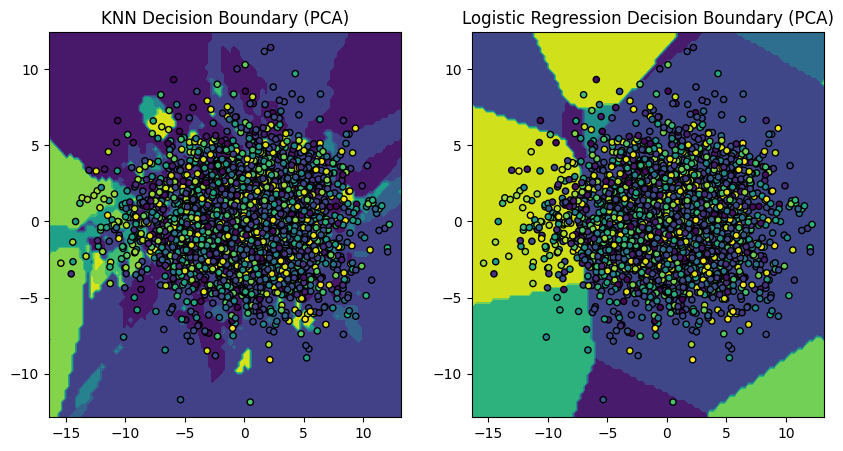

In [ ]:

from sklearn.inspection import DecisionBoundaryDisplay

# Train the KNN model
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_pca[:, :2], y_train)  # Use only the first two principal components

# Train the Logistic Regression model
logistic = LogisticRegression(max_iter=1000)
logistic.fit(X_train_pca[:, :2], y_train)  # Use only the first two principal components

# Plot the decision boundaries
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5))

# Decision boundary for KNN
DecisionBoundaryDisplay.from_estimator(knn, X_train_pca[:, :2], ax=ax1)
ax1.scatter(X_train_pca[:, 0], X_train_pca[:, 1], c=y_train, edgecolor="k", s=20)
ax1.set_title("KNN Decision Boundary (PCA)")

# Decision boundary for Logistic Regression
DecisionBoundaryDisplay.from_estimator(logistic, X_train_pca[:, :2], ax=ax2)
ax2.scatter(X_train_pca[:, 0], X_train_pca[:, 1], c=y_train, edgecolor="k", s=20)
ax2.set_title("Logistic Regression Decision Boundary (PCA)")

plt.show()



